In [2]:
import os
import cv2
import numpy as np
import zipfile
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

zip_path = "A,B,CNNS_with_Tim.zip"
extract_path = "data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
base_folder = os.path.join(extract_path, "A,B,CNNS_with_Tim")

train_path = os.path.join(base_folder, "veggie_heap_training")
test_path = os.path.join(base_folder, "veggie_heap_testing")


def load_dataset(folder_path, image_size=128):
    data = []
    labels = []

    for label in os.listdir(folder_path):
        class_path = os.path.join(folder_path, label)

        if not os.path.isdir(class_path):
            continue

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)

            img = cv2.imread(img_path)
            if img is None:
                continue

            img = cv2.resize(img, (image_size, image_size))
            img = img / 255.0

            data.append(img)
            labels.append(label)

    return np.array(data, dtype=np.float32), np.array(labels)
X_train, y_train = load_dataset(train_path)
X_test, y_test = load_dataset(test_path)

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)
le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

print("Classes:", le.classes_)
print("Encoded classes:",np.unique(y_train))

Training data shape: (9835, 128, 128, 3)
Training labels shape: (9835,)
Testing data shape: (2424, 128, 128, 3)
Testing labels shape: (2424,)
Classes: ["Apatosaur Aphie's Apples" "Bluplocephalus Bob's Blueberries"
 "Cherizinoasaur Cher's Cherries" "Corythosaurus Cory's Corn"
 "Grapthorina Greta's Grapes" "Pachycephalosaurus Perry's Peaches"
 "Pepteranodon Pep's Peppers" "Potoceratops Pott's Potatoes"
 "Rhaspdodon Ribery's Raspberries" "Stribecosaurus Stan's Strawberries"
 "Thyreosaur Tim's Thyme" 'vacation_photos']
Encoded classes: [ 0  1  2  3  4  5  6  7  8  9 10 11]


In [3]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to tensors
X_train = torch.tensor(X_train).permute(0,3,1,2)
X_test = torch.tensor(X_test).permute(0,3,1,2)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)



In [4]:
import torch.nn as nn
import torch.nn.functional as F

class VeggieCNN(nn.Module):
    def __init__(self, num_classes=12):
        super(VeggieCNN, self).__init__()

        # Block 1
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 3
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        # Block 4
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2,2)

        # Fully connected layers
        self.fc1 = nn.Linear(256 * 8 * 8, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))  # 128→64
        x = self.pool(F.relu(self.bn2(self.conv2(x))))  # 64→32
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # 32→16
        x = self.pool(F.relu(self.bn4(self.conv4(x))))  # 16→8

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VeggieCNN(num_classes=12).to(device)


In [5]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

epochs = 20


In [7]:
for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total
    print("Epoch ",(epoch+1/epochs)  ,"| Loss:" ,(running_loss/len(train_loader)) ,"| Train Acc:" ,(train_acc))


Epoch  0.05 | Loss: 0.2612754516243064 | Train Acc: 91.94712760549059
Epoch  1.05 | Loss: 0.18914203960055412 | Train Acc: 94.19420437214032
Epoch  2.05 | Loss: 0.1565574225682354 | Train Acc: 95.11947127605491
Epoch  3.05 | Loss: 0.12403845577425167 | Train Acc: 96.39044229791561
Epoch  4.05 | Loss: 0.11089999596860453 | Train Acc: 96.41077783426537
Epoch  5.05 | Loss: 0.10946106206166087 | Train Acc: 96.532791052364
Epoch  6.05 | Loss: 0.09275174980575684 | Train Acc: 97.06151499745806
Epoch  7.05 | Loss: 0.0857491950025308 | Train Acc: 97.39705134722928
Epoch  8.05 | Loss: 0.07837975133460023 | Train Acc: 97.39705134722928
Epoch  9.05 | Loss: 0.08063936237527008 | Train Acc: 97.53940010167769
Epoch  10.05 | Loss: 0.0659711279711866 | Train Acc: 98.1698017285206
Epoch  11.05 | Loss: 0.07852328227879782 | Train Acc: 97.70208439247585
Epoch  12.05 | Loss: 0.04847026944403828 | Train Acc: 98.55617691916625
Epoch  13.05 | Loss: 0.037943038580336874 | Train Acc: 98.83070665988815
Epoch  1

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

accuracy = accuracy_score(all_labels, all_preds)

print("Test Accuracy:", accuracy)
print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds))


Test Accuracy: 0.629950495049505

Classification Report:

              precision    recall  f1-score   support

           0       0.60      0.93      0.73       200
           1       0.34      1.00      0.51       200
           2       0.99      0.92      0.96       200
           3       0.99      1.00      0.99       217
           4       0.97      0.22      0.36       150
           5       1.00      0.10      0.17       199
           6       0.69      0.50      0.58       200
           7       0.59      0.47      0.52       200
           8       0.57      0.94      0.71       122
           9       0.63      0.99      0.77       150
          10       0.81      0.06      0.11       373
          11       0.70      0.99      0.82       213

    accuracy                           0.63      2424
   macro avg       0.74      0.68      0.60      2424
weighted avg       0.75      0.63      0.57      2424



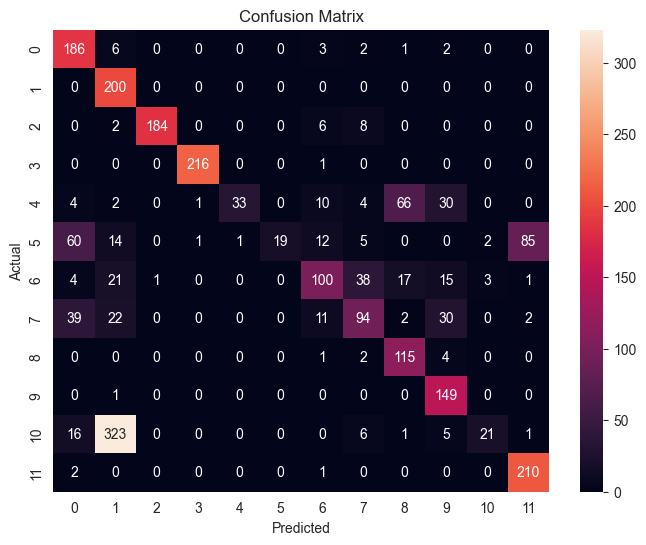

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
